# 02 · Análisis estadístico: Airbnb en Madrid

Contrastes de hipótesis, tamaños de efecto, intervalos bootstrap y regresión. Para cada test se muestran
**H0 y H1 antes de ejecutarlo** (definidas en `src/estadistica.py`), α = 0,05, los supuestos comprobados y la
conclusión. Se usan exactamente las mismas funciones que el pipeline, con la misma semilla, y se comprueba que
los resultados coinciden con `reports/findings.json`.

In [1]:
import sys
from pathlib import Path

sys.dont_write_bytecode = True
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import json

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src import analisis, config, estadistica as est, formato as fmt, visualizacion as viz

%matplotlib inline
viz.configurar_estilo()
df = pd.read_parquet(config.RUTA_PARQUET)
with open(config.RUTA_FINDINGS, encoding="utf-8") as f:
    findings = json.load(f)
cp = df[df["precio_valido"]]
rng = np.random.default_rng(config.SEMILLA)


def hipotesis(clave: str) -> None:
    """Muestra H0 y H1 de un contraste antes de ejecutarlo."""
    h0, h1 = est.HIPOTESIS[clave]
    display(Markdown(f"**H0:** {h0}  \n**H1:** {h1}  \n**α = {fmt.n2(config.ALFA)}**"))


def mostrar(resultado: est.ResultadoTest) -> None:
    """Resume un ResultadoTest."""
    efecto = resultado.tamano_efecto
    display(Markdown(
        f"- Estadístico = {fmt.n3(resultado.estadistico)}, {fmt.p_texto(resultado.p_valor)}\n"
        f"- {efecto['nombre']} = {fmt.n3(efecto['valor'])} (efecto {efecto['interpretacion']})\n"
        f"- Supuestos: {resultado.supuestos}\n"
        f"- **Conclusión:** {resultado.conclusion}"))

## 1. Normalidad del precio y de ln(precio)

Shapiro-Wilk sobre una muestra aleatoria acotada (semilla fija) y D'Agostino-K² sobre todos los datos.

In [2]:
hipotesis("normalidad")
r_precio = est.test_normalidad(cp["price"], "el precio", rng)
r_log = est.test_normalidad(cp["log_precio"], "el logaritmo del precio", rng)
mostrar(r_precio)
mostrar(r_log)
assert np.isclose(r_precio.estadistico, findings["estadistica"]["normalidad_precio"]["estadistico"])

**H0:** La variable procede de una distribución normal.  
**H1:** La variable no procede de una distribución normal.  
**α = 0,05**

- Estadístico = 49.774,065, p < 0,001
- asimetría y curtosis = 31,540 (efecto grande)
- Supuestos: {'n_total': 18785, 'n_muestra_shapiro': 5000, 'semilla_muestra': 'rng del pipeline'}
- **Conclusión:** Se rechaza H0 (p < α) con un efecto grande. El precio no es normal (asimetría 31,54, curtosis de exceso 1.469,92). Con n tan grande el test rechaza incluso desviaciones leves; la decisión de usar contrastes no paramétricos se apoya también en la asimetría y en los gráficos Q-Q.

- Estadístico = 1.014,390, p < 0,001
- asimetría y curtosis = 0,212 (efecto grande)
- Supuestos: {'n_total': 18785, 'n_muestra_shapiro': 5000, 'semilla_muestra': 'rng del pipeline'}
- **Conclusión:** Se rechaza H0 (p < α) con un efecto grande. El logaritmo del precio no es normal (asimetría 0,21, curtosis de exceso 2,01). Con n tan grande el test rechaza incluso desviaciones leves; la decisión de usar contrastes no paramétricos se apoya también en la asimetría y en los gráficos Q-Q.

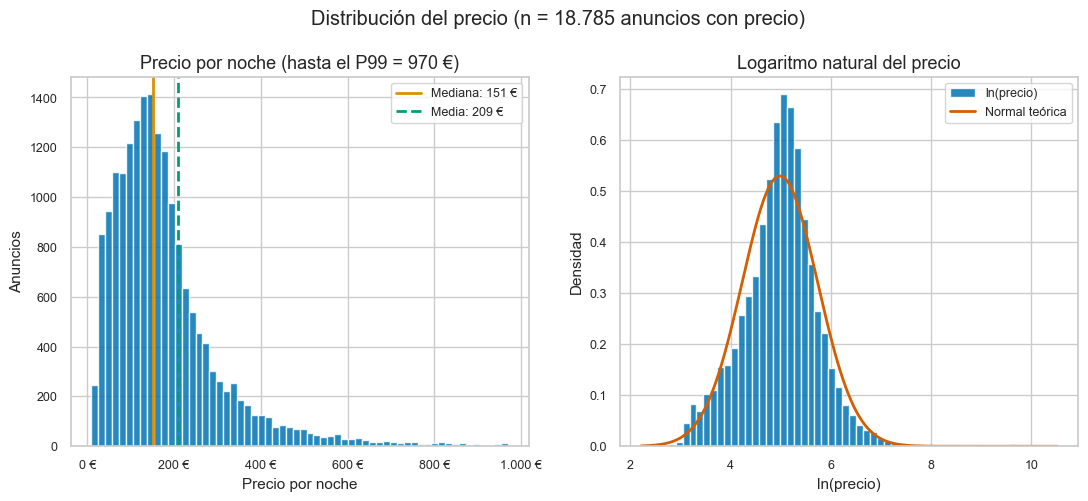

In [3]:
viz.fig_distribucion_precio(df);

## 2. Mann-Whitney U: superhosts frente a no superhosts

In [4]:
hipotesis("mann_whitney_superhost")
sh = cp["host_is_superhost"]
r_mw = est.mann_whitney(cp.loc[sh, "price"], cp.loc[~sh, "price"], "superhosts", "no superhosts",
                        "mann_whitney_superhost")
mostrar(r_mw)
assert np.isclose(r_mw.tamano_efecto["valor"], findings["estadistica"]["mann_whitney_superhost"]["tamano_efecto"]["valor"])

**H0:** El precio de los anuncios de superhosts y de no superhosts tiene la misma distribución (P(X_superhost > X_no) = 0,5).  
**H1:** Las distribuciones difieren (contraste bilateral).  
**α = 0,05**

- Estadístico = 38.271.719,000, p < 0,001
- correlación rank-biserial = 0,100 (efecto despreciable)
- Supuestos: {'datos_ordinales': True, 'independencia': 'parcial: un anfitrión puede tener varios anuncios (ver análisis de sensibilidad)', 'nota': 'compara dominancia estocástica, no solo medianas, si las formas difieren'}
- **Conclusión:** Se rechaza H0 (p < α): resultado estadísticamente significativo pero con efecto despreciable, sin relevancia práctica. Los anuncios de superhosts tienden a tener precios más altos (mediana de superhosts: 163,50 €; de no superhosts: 147,00 €). Es una asociación bruta, sin controlar por ubicación ni tipo.

**Sensibilidad (independencia):** el pipeline repite el contraste con un anuncio por anfitrión.

In [5]:
s = findings["estadistica"]["sensibilidad_un_anuncio_por_host"]
print("n =", fmt.n0(s["n"]), "| r =", fmt.n3(s["mann_whitney_superhost"]["tamano_efecto"]["valor"]),
      "|", fmt.p_texto(s["mann_whitney_superhost"]["p_valor"]), "| misma decisión:", s["misma_decision_superhost"])

n = 6.546 | r = 0,078 | p < 0,001 | misma decisión: True


## 3. Kruskal-Wallis: precio por tipo de habitación y por distrito

Las categorías con pocos anuncios con precio (compartida y hotel, por debajo de `config.MIN_N_CATEGORIA_RARA`)
se agrupan; los grupos por debajo de `config.MIN_N_GRUPO` se excluyen de la inferencia.

In [6]:
print("Umbral de agrupación:", config.MIN_N_CATEGORIA_RARA, "| mínimo por grupo:", config.MIN_N_GRUPO)

Umbral de agrupación: 200 | mínimo por grupo: 30


In [7]:
hipotesis("kruskal_tipo")
r_kt = est.kruskal(cp, "price", "tipo_habitacion_agrupado", "kruskal_tipo", "tipos de habitación")
mostrar(r_kt)

**H0:** La distribución del precio es la misma en todos los tipos de habitación.  
**H1:** Al menos un tipo de habitación tiene una distribución de precio distinta.  
**α = 0,05**

- Estadístico = 4.403,947, p < 0,001
- épsilon cuadrado = 0,234 (efecto grande)
- Supuestos: {'independencia': 'parcial (anfitriones con varios anuncios)', 'min_n_por_grupo': 30, 'n_grupos': 3}
- **Conclusión:** Se rechaza H0 (p < α) con un efecto grande. El precio difiere entre tipos de habitación: la mediana más alta es la de Alojamiento entero y la más baja la de Otras (compartida + hotel).

In [8]:
hipotesis("kruskal_distrito")
r_kd = est.kruskal(cp, "price", "neighbourhood_group_cleansed", "kruskal_distrito", "distritos")
mostrar(r_kd)
assert np.isclose(r_kd.estadistico, findings["estadistica"]["kruskal_distrito"]["estadistico"])

**H0:** La distribución del precio es la misma en todos los distritos (n ≥ 30).  
**H1:** Al menos un distrito tiene una distribución de precio distinta.  
**α = 0,05**

- Estadístico = 2.296,341, p < 0,001
- épsilon cuadrado = 0,122 (efecto mediano)
- Supuestos: {'independencia': 'parcial (anfitriones con varios anuncios)', 'min_n_por_grupo': 30, 'n_grupos': 21}
- **Conclusión:** Se rechaza H0 (p < α) con un efecto mediano. El precio difiere entre distritos: la mediana más alta es la de Salamanca y la más baja la de Moratalaz.

### Post-hoc de Dunn con corrección de Bonferroni

In [9]:
hipotesis("posthoc")
ph = findings["estadistica"]["posthoc_distrito"]
print(ph["metodo"], "|", ph["n_pares_significativos"], "de", ph["n_pares"], "pares significativos")
pd.DataFrame(ph["pares"]).sort_values("p_ajustado").head(10).round(4)

**H0:** Para cada par de grupos, no hay diferencia en la distribución del precio.  
**H1:** El par de grupos difiere (p ajustado por Bonferroni < α).  
**α = 0,05**

Dunn con corrección de Bonferroni (scikit-posthocs) | 36 de 45 pares significativos


,grupo_a,grupo_b,p_ajustado,significativo,dif_medianas,rank_biserial
23,Centro,Tetuán,0.0,True,53.00,0.3612
9,Carabanchel,Centro,0.0,True,-72.50,-0.4984
20,Centro,Puente de Vallecas,0.0,True,73.00,0.5074
15,Carabanchel,Salamanca,0.0,True,-80.84,-0.5201
40,Puente de Vallecas,Salamanca,0.0,True,-81.34,-0.5275
44,Salamanca,Tetuán,0.0,True,61.34,0.3905
19,Centro,Ciudad Lineal,0.0,True,52.00,0.3576
37,Ciudad Lineal,Salamanca,0.0,True,-60.34,-0.3834
1,Arganzuela,Centro,0.0,True,-33.43,-0.2380
31,Chamberí,Puente de Vallecas,0.0,True,48.40,0.3090


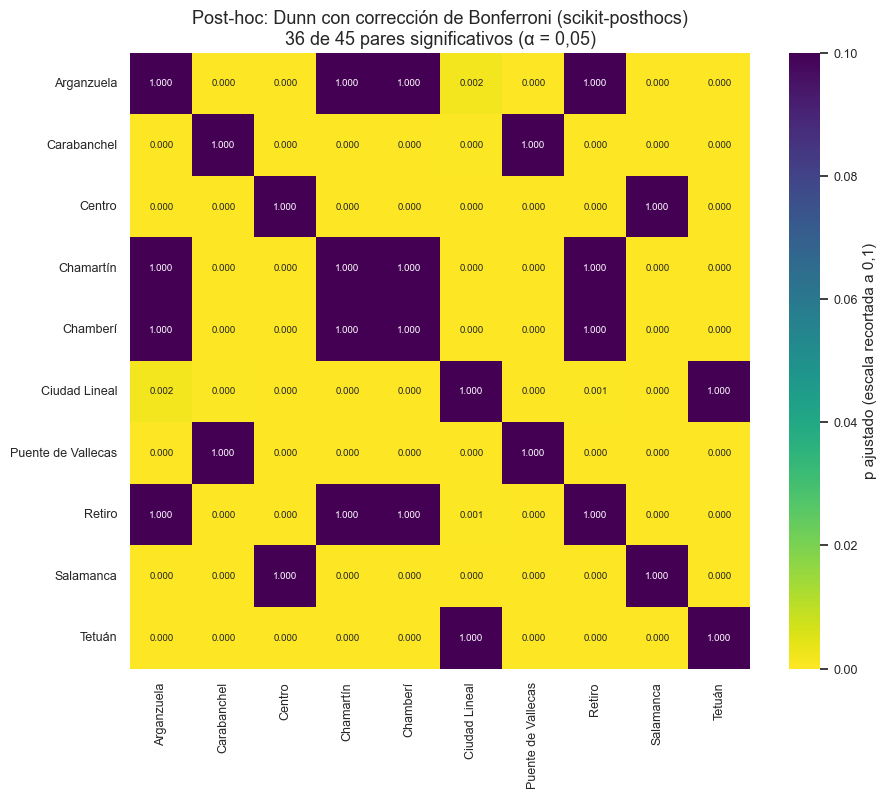

In [10]:
viz.fig_posthoc_distritos(findings);

## 4. Chi-cuadrado con V de Cramér

In [11]:
for clave, fila, col, etiqueta in [
    ("chi2_tipo_superhost", "tipo_habitacion_agrupado", "host_is_superhost", "tipo de habitación y ser superhost"),
    ("chi2_multi_tipo", "es_multianuncio", "tipo_habitacion_agrupado", "ser multi-anuncio y tipo de habitación"),
]:
    hipotesis(clave)
    mostrar(est.chi_cuadrado(df, fila, col, clave, etiqueta))

**H0:** El tipo de habitación y ser superhost son independientes.  
**H1:** Existe asociación entre tipo de habitación y ser superhost.  
**α = 0,05**

- Estadístico = 181,136, p < 0,001
- V de Cramér = 0,089 (efecto despreciable)
- Supuestos: {'min_esperada': 45.72140724393093, 'pct_celdas_esperada_menor_5': 0.0, 'cumple_esperadas': True, 'correccion_yates': False}
- **Conclusión:** Se rechaza H0 (p < α): resultado estadísticamente significativo pero con efecto despreciable, sin relevancia práctica. Hay asociación entre tipo de habitación y ser superhost (V de Cramér = 0,089).

**H0:** Ser anfitrión multi-anuncio y el tipo de habitación son independientes.  
**H1:** Existe asociación entre ser multi-anuncio y el tipo de habitación.  
**α = 0,05**

- Estadístico = 178,117, p < 0,001
- V de Cramér = 0,088 (efecto despreciable)
- Supuestos: {'min_esperada': 50.83941321563027, 'pct_celdas_esperada_menor_5': 0.0, 'cumple_esperadas': True, 'correccion_yates': False}
- **Conclusión:** Se rechaza H0 (p < α): resultado estadísticamente significativo pero con efecto despreciable, sin relevancia práctica. Hay asociación entre ser multi-anuncio y tipo de habitación (V de Cramér = 0,088).

In [12]:
hipotesis("chi2_distrito_tipo")
r = findings["estadistica"]["chi2_distrito_tipo"]
print("V de Cramér =", fmt.n3(r["tamano_efecto"]["valor"]), "|", fmt.p_texto(r["p_valor"]),
      "| % celdas con esperada < 5:", fmt.pct1(r["supuestos"]["pct_celdas_esperada_menor_5"]))
print("Conclusión:", r["conclusion"])

**H0:** El distrito y el tipo de habitación son independientes.  
**H1:** Existe asociación entre distrito y tipo de habitación.  
**α = 0,05**

V de Cramér = 0,169 | p < 0,001 | % celdas con esperada < 5: 13,0 %
Conclusión: Se rechaza H0 (p < α) con un efecto pequeño. Hay asociación entre distrito y tipo de habitación (V de Cramér = 0,169).


## 5. Intervalos de confianza bootstrap de la mediana

In [13]:
b = findings["estadistica"]["bootstrap"]
pd.concat([pd.DataFrame(b["tipo"]), pd.DataFrame(b["distritos"])]).round(2)

,grupo,n,mediana,ic_inf,ic_sup,n_boot
0,Alojamiento entero,13561,173.63,172.00,175.36,2000
1,Habitación privada,5059,74.00,71.10,75.60,2000
2,Otras (compartida + hotel),165,29.00,27.00,35.00,2000
0,Salamanca,1314,188.34,180.16,194.25,2000
1,Centro,7866,180.00,177.30,182.35,2000
2,Chamberí,1159,155.40,148.60,161.85,2000
3,Chamartín,699,150.70,144.68,157.00,2000
4,Arganzuela,918,146.57,138.00,151.01,2000
5,Retiro,656,145.48,137.60,156.07,2000
6,Ciudad Lineal,631,128.00,121.30,133.60,2000


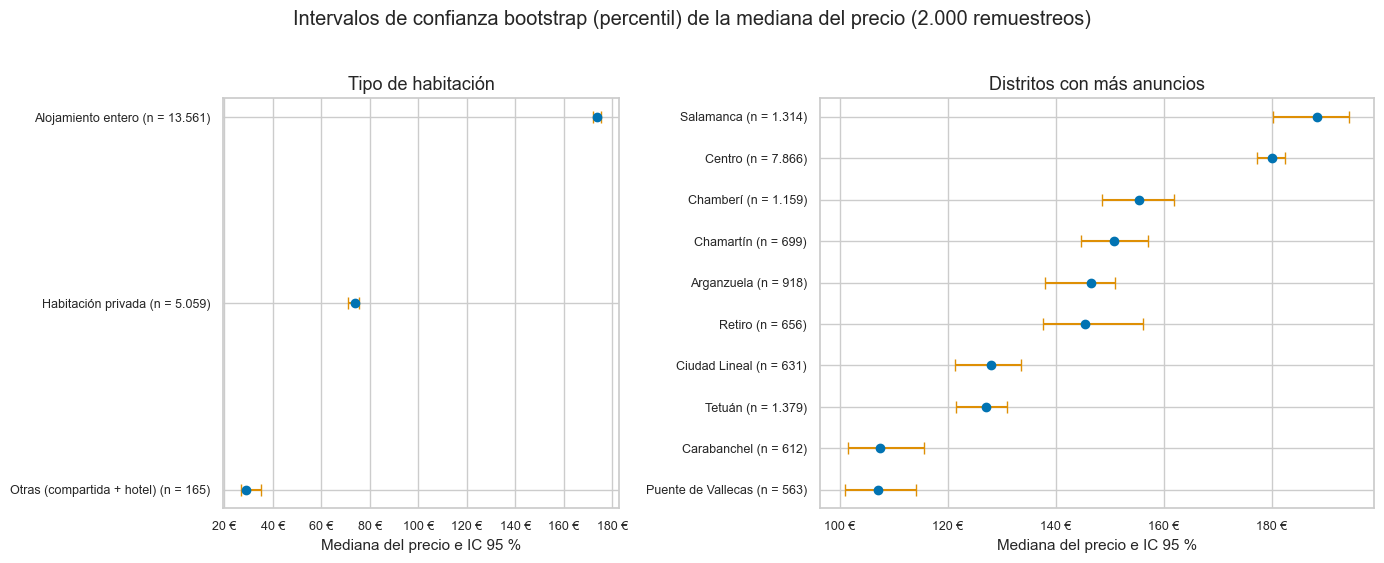

In [14]:
viz.fig_ic_bootstrap(findings);

## 6. Regresión OLS sobre ln(precio)

Errores agrupados por anfitrión (y HC3 como comparación), Breusch-Pagan, Jarque-Bera, VIF y coeficientes
interpretados como cambio porcentual `100·(e^β − 1)`.

In [15]:
hipotesis("ols")
ols = est.ajustar_ols(df, config.CIUDADES[config.CIUDAD_POR_DEFECTO].distrito_referencia)
artefactos = {"residuos": ols.pop("_residuos"), "ajustados": ols.pop("_ajustados")}
print("n efectivo:", fmt.n0(ols["n_efectivo"]), "| R² ajustado:", fmt.n3(ols["r2_ajustado"]))
print("Diagnóstico:", {k: round(v, 4) if isinstance(v, float) else v for k, v in ols["diagnostico"].items()})
assert np.isclose(ols["r2_ajustado"], findings["estadistica"]["ols"]["r2_ajustado"])
coef = pd.DataFrame(ols["coeficientes"])
coef.loc[~coef["es_distrito"], ["nombre", "pct", "ic_inf_pct", "ic_sup_pct", "p_cluster", "p_hc3"]].round(4)

**H0:** Cada coeficiente β es 0 (la variable no se asocia con ln(precio) controlando por el resto).  
**H1:** β ≠ 0.  
**α = 0,05**

n efectivo: 18.159 | R² ajustado: 0,571
Diagnóstico: {'breusch_pagan_lm': 1601.873, 'breusch_pagan_p': 0.0, 'heterocedasticidad': True, 'jarque_bera': 3173.5961, 'jarque_bera_p': 0.0, 'asimetria_residuos': 0.4906, 'curtosis_residuos': 4.7977, 'n_cook_mayor_4_n': 963}


,nombre,pct,ic_inf_pct,ic_sup_pct,p_cluster,p_hc3
0,Tipo: Habitación privada,-22.8184,-28.3073,-16.9092,0.0000,0.0000
1,Tipo: Otras (compartida + hotel),-43.6571,-57.1361,-25.9395,0.0000,0.0000
2,Licencia: Con nº de registro,1.6198,-2.5905,6.0121,0.4567,0.0761
3,Licencia: Exenta,-0.2765,-4.7103,4.3635,0.9050,0.7131
4,Licencia: Otro / en proceso,12.6545,-0.5975,27.6733,0.0620,0.0024
25,Capacidad (+1 persona),11.9753,10.3948,13.5784,0.0000,0.0000
26,Dormitorios (+1),4.5632,1.5937,7.6195,0.0024,0.0061
27,Baños (+1),-0.2869,-4.4488,4.0564,0.8949,0.7085
28,Baño compartido,-26.4491,-32.8129,-19.4825,0.0000,0.0000
29,Amenities (+1),0.3261,0.1820,0.4704,0.0000,0.0000


In [16]:
pd.DataFrame(ols["vif"])[["nombre", "vif"]].round(2)

,nombre,vif
0,Capacidad (+1 persona),2.20
1,Tipo: Habitación privada,2.15
2,Baño compartido,1.82
3,Dormitorios (+1),1.81
4,Amenities (+1),1.77
5,ln(1 + nº reseñas),1.55
6,Parking,1.33
7,Baños (+1),1.32
8,Estancia mínima ≥ 30 noches,1.26
9,Licencia: Exenta,1.25


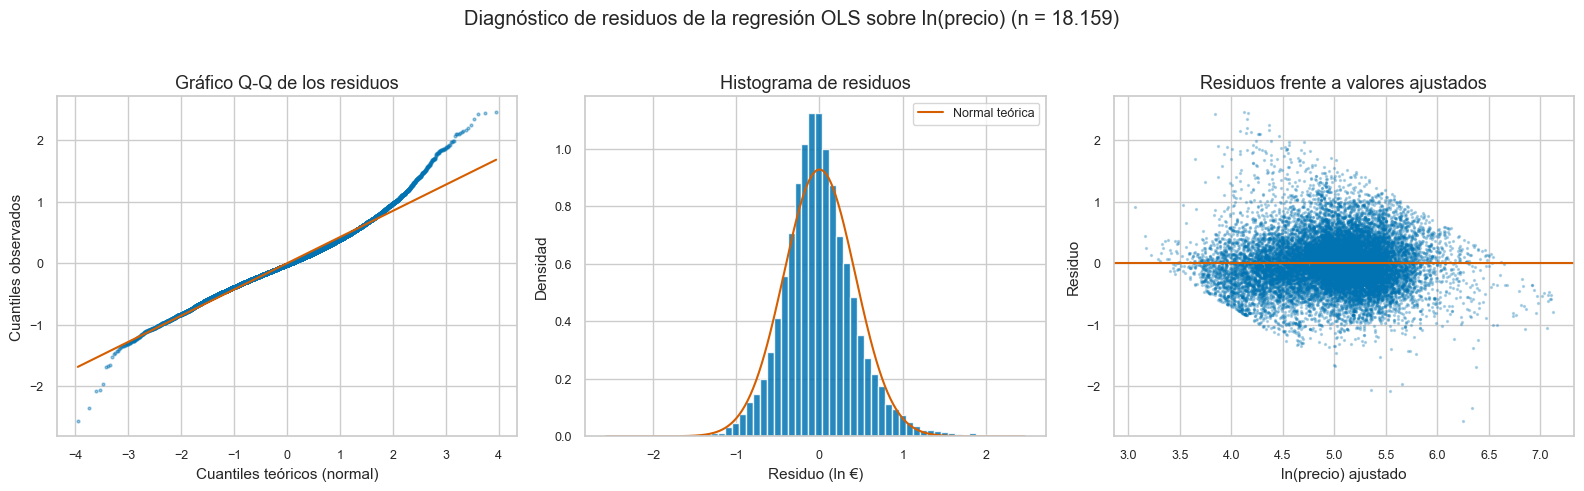

In [17]:
viz.fig_ols_residuos(artefactos);

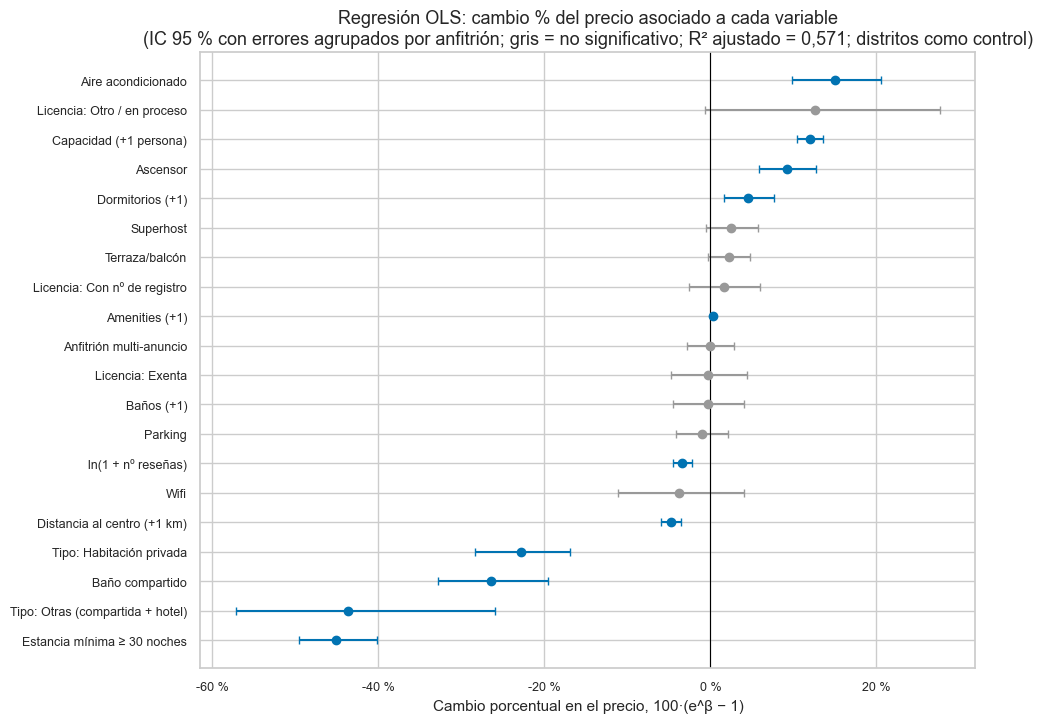

In [18]:
viz.fig_ols_coeficientes(findings);

## 7. Modelo predictivo (complementario)

HistGradientBoosting con lista blanca de variables (sin fuga del precio), partición train/test con semilla y
línea base. La importancia por permutación es predictiva, no causal.

R² test: 0,740 | R² línea base: -0,005 | MAE ≈ 60 € (base 103 €)


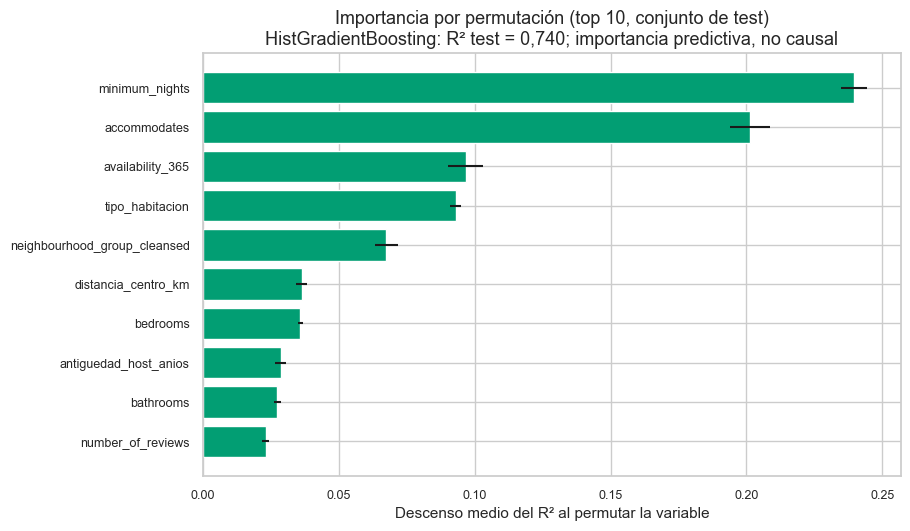

In [19]:
ml = findings["estadistica"]["ml"]
if ml["ejecutado"]:
    print("R² test:", fmt.n3(ml["r2_test"]), "| R² línea base:", fmt.n3(ml["r2_base"]),
          "| MAE ≈", fmt.eur0(ml["mae_eur_test"]), "(base", fmt.eur0(ml["mae_eur_base"]) + ")")
    viz.fig_importancia_variables(findings)
else:
    print("Modelo no ejecutado:", ml["motivo"])

## Conclusión

Las diferencias por tipo de habitación y distrito son significativas y relevantes; la de superhost es significativa
pero despreciable y desaparece al controlar en la regresión. La interpretación completa y las limitaciones están en
`reports/informe.md`.